# Lab 7: Visual Wake Words using Transfer Learning

**Aim:** Build a person / no-person classifier from COCO 2017 using MobileNetV2 transfer learning, then deploy an INT8 TensorFlow Lite model and test it with a phone camera.

**Workflow:** COCO download → person/no-person labels → balanced 70:15:15 split → 96×96 image pipeline → frozen MobileNetV2 head training → fine-tuning → test metrics → INT8 conversion → five live camera tests.

**Labels:** `person = 1` when the sum of COCO person-instance areas is at least 0.5% of the image area. `no_person = 0` when there are no person annotations. Images containing only tiny people (below the threshold) are excluded as ambiguous, following the reference notebook's approach.

## 1. Setup

Run this notebook in Google Colab. Enable a GPU under **Runtime → Change runtime type** if available. The COCO validation images are a large download (approximately 1 GB), so allow time and storage.

In [ ]:
!pip -q install pycocotools

import os, random, time, json, base64, io
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score
from tensorflow.keras import layers
from IPython.display import display, Javascript, HTML

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG, BATCH, PER_CLASS = 96, 32, 800
CLASS_NAMES = ["no_person", "person"]
print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

## 2. Download COCO 2017 validation images and annotations

The validation split contains 5,000 images. We use its instance annotations to identify person objects. The following cell downloads and extracts the image archive and the validation annotation JSON.

In [ ]:
!wget -q -nc http://images.cocodataset.org/zips/val2017.zip
!wget -q -nc http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -q -n val2017.zip
!unzip -q -n annotations_trainval2017.zip annotations/instances_val2017.json

print("COCO images:", len(os.listdir("val2017")))
print("Annotation file exists:", os.path.exists("annotations/instances_val2017.json"))

## 3. Label images using the 0.5% person-area rule

For each image, sum the annotated `area` values for all person instances and divide by the image area. A ratio of 0.005 or more is labelled `person`. Images with no person annotations are labelled `no_person`. Images containing people below the threshold are skipped to avoid ambiguous labels.

We then randomly select exactly 800 images from each class.

In [ ]:
coco = COCO("annotations/instances_val2017.json")
person_id = coco.getCatIds(catNms=["person"])[0]
pos, neg, tiny = [], [], []

for img_id in coco.getImgIds():
    info = coco.loadImgs(img_id)[0]
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[img_id], catIds=[person_id]))
    path = os.path.join("val2017", info["file_name"])

    if not anns:
        neg.append(path)
    else:
        ratio = sum(a["area"] for a in anns) / (info["width"] * info["height"])
        if ratio >= 0.005:
            pos.append(path)
        else:
            tiny.append(path)

print(f"Person candidates: {len(pos)}")
print(f"No-person candidates: {len(neg)}")
print(f"Excluded tiny-person images: {len(tiny)}")

assert len(pos) >= PER_CLASS and len(neg) >= PER_CLASS, "Not enough images for 800 per class."
random.shuffle(pos); random.shuffle(neg)
pos, neg = pos[:PER_CLASS], neg[:PER_CLASS]
paths = np.array(pos + neg)
labels = np.array([1]*PER_CLASS + [0]*PER_CLASS, dtype=np.int32)

display(pd.DataFrame({
    "class": CLASS_NAMES,
    "selected_images": [len(neg), len(pos)]
}))

## 4. Create balanced train, validation and test sets

The selected 1,600 images are split using stratification: 70% training, 15% validation and 15% testing. Stratification preserves the same class balance in all three sets.

In [ ]:
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

split_table = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_val).value_counts(),
    "test": pd.Series(y_test).value_counts()
}).reindex([0,1]).fillna(0).astype(int)
split_table.index = CLASS_NAMES
display(split_table)

## 5. Inspect examples from both classes

The sample grid is a quick label sanity check. The model receives resized 96×96 RGB images; the displayed samples are original images.

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for row, (plist, title) in enumerate([(neg, "no_person"), (pos, "person")]):
    for ax, path in zip(axes[row], plist[:4]):
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Build the image input pipeline

Images are decoded as RGB, resized to 96×96 and converted to float values in the range expected by MobileNetV2 (`[-1, 1]`). Training images receive random horizontal flips and light contrast/brightness augmentation.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label, training=False):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMG, IMG))
    image = tf.cast(image, tf.float32)
    if training:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, max_delta=12)
        image = tf.image.random_contrast(image, 0.9, 1.1)
    image = tf.clip_by_value(image, 0, 255)
    image = image / 127.5 - 1.0
    return image, label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(lambda a,b: load_image(a,b,training),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, True)
val_ds = make_ds(p_val, y_val)
test_ds = make_ds(p_test, y_test)
xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, "Pixel range:", float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))

## 7. Build MobileNetV2 transfer-learning model (α = 0.35)

The ImageNet-pretrained MobileNetV2 base is frozen first. A global-average-pooling layer, dropout and a two-class softmax head are added. The parameter report distinguishes frozen feature-extractor parameters from trainable classification-head parameters.

In [ ]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG, IMG, 3), alpha=0.35,
    include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input((IMG, IMG, 3))
features = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(features)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(2, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

def parameter_report(model):
    total = model.count_params()
    trainable = sum(int(tf.size(w)) for w in model.trainable_weights)
    frozen = total - trainable
    print(f"Total parameters:     {total:,}")
    print(f"Trainable parameters: {trainable:,}")
    print(f"Frozen parameters:    {frozen:,}")

parameter_report(model)
model.summary()

## 8. Train the new classification head

Only the new dense head is trainable in this stage. The pretrained MobileNetV2 weights remain frozen so the model first learns how to map the extracted visual features to `person` and `no_person`.

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

head_history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=8, callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=3, restore_best_weights=True, monitor="val_loss")
    ])

Epoch 1/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 315ms/step - accuracy: 0.6348 - loss: 0.6731 - val_accuracy: 0.7583 - val_loss: 0.5001
Epoch 2/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 304ms/step - accuracy: 0.7777 - loss: 0.4827 - val_accuracy: 0.7875 - val_loss: 0.4760
Epoch 3/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 311ms/step - accuracy: 0.8188 - loss: 0.4136 - val_accuracy: 0.8083 - val_loss: 0.4565
Epoch 4/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 245ms/step - accuracy: 0.8241 - loss: 0.3921 - val_accuracy: 0.8000 - val_loss: 0.4434
Epoch 5/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 13s 378ms/step - accuracy: 0.8348 - loss: 0.3776 - val_accuracy: 0.8042 - val_loss: 0.4440
Epoch 6/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 16s 232ms/step - accuracy: 0.8446 - loss: 0.3513 - val_accuracy: 0.7917 - val_loss: 0.4566
Epoch 7/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 305ms/step - accuracy: 0.8482 - loss: 0.3397 - val_accuracy: 0.8083 - val_loss: 0.4544


## 9. Fine-tune the top MobileNetV2 layers

Unfreeze only the top 20 layers of the base model and train with a much smaller learning rate. Batch-normalisation layers are kept frozen for stable fine-tuning on this relatively small dataset.

In [9]:
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

fine_history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=8, callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=3, restore_best_weights=True, monitor="val_loss")
    ])

parameter_report(model)

Epoch 1/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 391ms/step - accuracy: 0.8348 - loss: 0.3663 - val_accuracy: 0.8042 - val_loss: 0.4425
Epoch 2/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 353ms/step - accuracy: 0.8509 - loss: 0.3405 - val_accuracy: 0.8083 - val_loss: 0.4415
Epoch 3/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 284ms/step - accuracy: 0.8438 - loss: 0.3519 - val_accuracy: 0.8125 - val_loss: 0.4431
Epoch 4/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 321ms/step - accuracy: 0.8536 - loss: 0.3511 - val_accuracy: 0.8042 - val_loss: 0.4445
Epoch 5/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 349ms/step - accuracy: 0.8491 - loss: 0.3320 - val_accuracy: 0.8125 - val_loss: 0.4469
Total parameters:     412,770
Trainable parameters: 246,050
Frozen parameters:    166,720


## 10. Plot training and validation accuracy

The curves combine both training stages. A widening gap between training and validation accuracy can indicate overfitting.

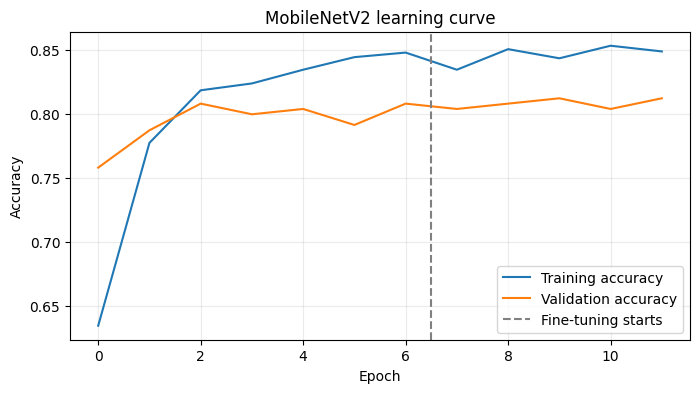

In [10]:
train_acc = head_history.history["accuracy"] + fine_history.history["accuracy"]
val_acc = head_history.history["val_accuracy"] + fine_history.history["val_accuracy"]
plt.figure(figsize=(8,4))
plt.plot(train_acc, label="Training accuracy")
plt.plot(val_acc, label="Validation accuracy")
plt.axvline(len(head_history.history["accuracy"])-0.5, ls="--", color="gray", label="Fine-tuning starts")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("MobileNetV2 learning curve")
plt.legend(); plt.grid(alpha=.25); plt.show()

## 11. Evaluate on the held-out test set

Report accuracy, precision and recall, then inspect the confusion matrix. In this application, a **false negative** (a person predicted as no-person) is especially important because the system could switch lights off while someone is present.

Test accuracy:  0.8000
Person precision: 0.8000
Person recall:    0.8000
              precision    recall  f1-score   support

   no_person       0.80      0.80      0.80       120
      person       0.80      0.80      0.80       120

    accuracy                           0.80       240
   macro avg       0.80      0.80      0.80       240
weighted avg       0.80      0.80      0.80       240



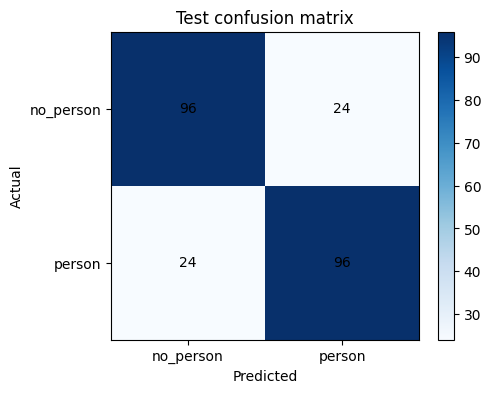

In [11]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
probs = model.predict(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = probs.argmax(axis=1)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
print(f"Test accuracy:  {test_acc:.4f}")
print(f"Person precision: {precision:.4f}")
print(f"Person recall:    {recall:.4f}")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5,4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0,1], CLASS_NAMES); ax.set_yticks([0,1], CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Test confusion matrix")
for (i,j), value in np.ndenumerate(cm):
    ax.text(j,i,str(value),ha="center",va="center")
plt.colorbar(im); plt.show()

## 12. Inspect misclassified test images

The following grid displays up to 12 incorrect predictions with their true label, predicted label and person probability. Use these examples to identify difficult cases such as distant people, occlusion, unusual lighting or cluttered backgrounds.

Misclassified images: 48 of 240


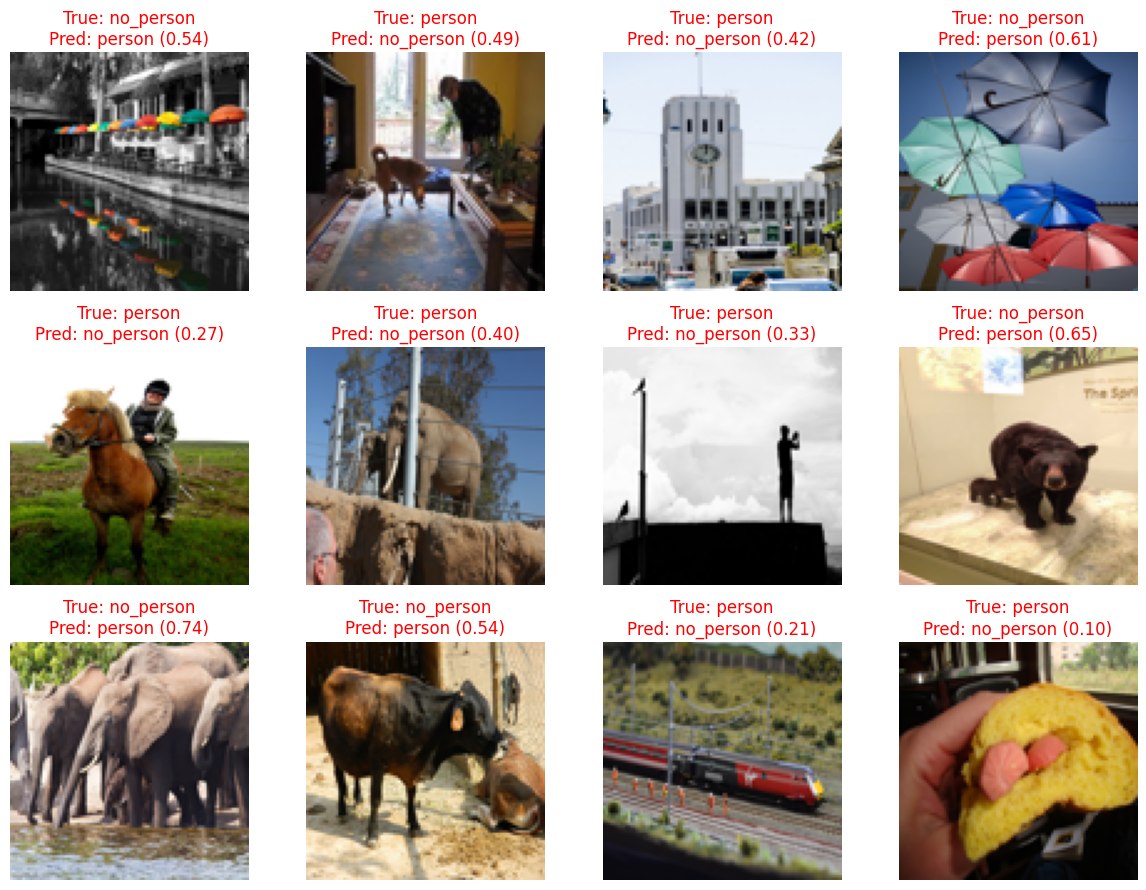

In [12]:
wrong = np.where(y_pred != y_true)[0]
print("Misclassified images:", len(wrong), "of", len(y_true))
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(12,9))
    for ax, idx in zip(axes.ravel(), wrong[:12]):
        img = Image.open(p_test[idx]).convert("RGB").resize((IMG,IMG))
        ax.imshow(img)
        ax.set_title(f"True: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]} ({probs[idx,1]:.2f})",
                     color="red")
        ax.axis("off")
    for ax in axes.ravel()[min(len(wrong),12):]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 13. Choose a wake-up threshold using validation data

The default threshold is 0.5, but the library use case should avoid missing people. We compare thresholds on validation data. A lower person threshold generally improves recall (fewer missed people) at the cost of more false wakes (lights remain on unnecessarily). Choose a threshold based on the safety/energy trade-off, not accuracy alone.

In [13]:
val_probs = model.predict(val_ds, verbose=0)[:,1]
val_true = np.concatenate([y.numpy() for _, y in val_ds])
threshold_rows = []
for th in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    pred = (val_probs >= th).astype(int)
    threshold_rows.append({
        "threshold": th,
        "precision": precision_score(val_true, pred, zero_division=0),
        "recall": recall_score(val_true, pred, zero_division=0),
        "missed_people": int(((pred==0)&(val_true==1)).sum()),
        "false_wakes": int(((pred==1)&(val_true==0)).sum())
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

,threshold,precision,recall,missed_people,false_wakes
0,0.2,0.639,0.900,12,61
1,0.3,0.710,0.858,17,42
2,0.4,0.782,0.808,23,27
3,0.5,0.836,0.767,28,18
4,0.6,0.851,0.717,34,15
5,0.7,0.894,0.700,36,10
6,0.8,0.937,0.617,46,5


## 14. Convert the model to full INT8 TensorFlow Lite

A representative dataset calibrates activation ranges. We request integer-only built-in operations and INT8 input/output. The exported model can be evaluated on the test images to compare its accuracy with the float Keras model.

In [14]:
# Float32 TFLite baseline
float_converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float = float_converter.convert()
with open("vww_mobilenetv2_float32.tflite", "wb") as f:
    f.write(tflite_float)

# Full INT8 TFLite
def representative_data():
    for images, _ in train_ds.unbatch().take(200):
        yield [images[None, ...].numpy().astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_int8 = converter.convert()

with open("vww_mobilenetv2_int8.tflite", "wb") as f:
    f.write(tflite_int8)
print("Float32 TFLite:", round(len(tflite_float)/1024, 1), "KB")
print("INT8 TFLite:", round(len(tflite_int8)/1024, 1), "KB")
print("INT8 under 1 MB:", len(tflite_int8) < 1024*1024)

Saved artifact at '/tmp/tmpr9y7huby'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  138664705304592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705304400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705305360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705305552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705305168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705305744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705304784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705306512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705304976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705303248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138664705306

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Float32 TFLite: 1584.9 KB
INT8 TFLite: 627.9 KB
INT8 under 1 MB: True


## 15. Evaluate INT8 TFLite and compare with float model

The helper quantises each input image using the model's input scale and zero-point, runs the TFLite interpreter, and dequantises the output scores. The comparison reports actual file size and test accuracy.

In [15]:
def tflite_predict(images, model_bytes):
    interpreter = tf.lite.Interpreter(model_content=model_bytes)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    in_scale, in_zero = inp["quantization"]
    out_scale, out_zero = out["quantization"]
    predictions, scores_all = [], []

    for image in images:
        x = image.numpy() if hasattr(image, "numpy") else image
        if inp["dtype"] == np.int8:
            x = np.clip(np.round(x/in_scale + in_zero), -128, 127).astype(np.int8)
        else:
            x = x.astype(np.float32)
        interpreter.set_tensor(inp["index"], x[None, ...])
        interpreter.invoke()
        raw = interpreter.get_tensor(out["index"])[0]
        if out["dtype"] == np.int8:
            scores = (raw.astype(np.float32)-out_zero)*out_scale
        else:
            scores = raw.astype(np.float32)
        scores_all.append(scores)
        predictions.append(int(np.argmax(scores)))
    return np.array(predictions), np.array(scores_all)

test_images = np.concatenate([x.numpy() for x,_ in test_ds], axis=0)
float_tflite_pred, float_tflite_scores = tflite_predict(test_images, tflite_float)
int8_pred, int8_scores = tflite_predict(test_images, tflite_int8)
keras_acc = float((y_pred == y_true).mean())
float_tflite_acc = float((float_tflite_pred == y_true).mean())
int8_acc = float((int8_pred == y_true).mean())

comparison = pd.DataFrame([
    {"model":"Keras float32","size_KB":None,"test_accuracy":keras_acc},
    {"model":"TFLite float32","size_KB":len(tflite_float)/1024,"test_accuracy":float_tflite_acc},
    {"model":"TFLite INT8","size_KB":len(tflite_int8)/1024,"test_accuracy":int8_acc}
])
display(comparison.round(4))
print("INT8 vs float TFLite accuracy change (percentage points):",
      round((int8_acc-float_tflite_acc)*100,2))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,model,size_KB,test_accuracy
0,Keras float32,NaN,0.8000
1,TFLite float32,1584.9180,0.8000
2,TFLite INT8,627.8984,0.7875


INT8 vs float TFLite accuracy change (percentage points): -1.25


## 16. Five live phone-camera tests

Open this notebook in Colab on a smartphone browser (or use a laptop webcam), allow camera permission, and run the cell. Capture five separate frames. Each frame is resized and passed to the **INT8 TFLite** model locally in the Colab runtime. The browser sends only the still image for each capture; no cloud vision API is used.

For a real library system, the phone test is a prototype only. The deployed camera and microcontroller must run the same model locally.


Capture Test Image 1
Position yourself or point the camera at an empty scene.
Click the Capture Image button when ready.

Prediction Result:


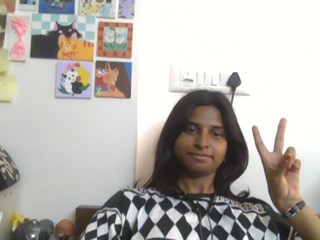

Person Confidence Score: 0.980
Status: PERSON DETECTED
Decision: PERSON / LIGHTS ON
--------------------------------------------------

Capture Test Image 2
Position yourself or point the camera at an empty scene.
Click the Capture Image button when ready.

Prediction Result:


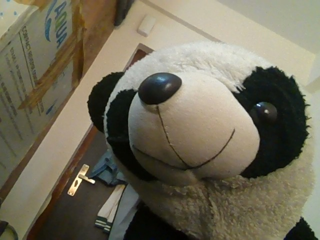

Person Confidence Score: 0.156
Status: NO PERSON DETECTED
Decision: NO PERSON / LIGHTS MAY DIM
--------------------------------------------------

Capture Test Image 3
Position yourself or point the camera at an empty scene.
Click the Capture Image button when ready.

Prediction Result:


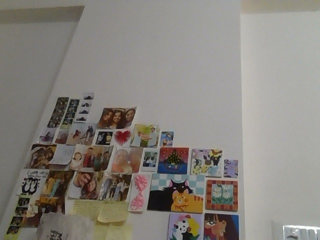

Person Confidence Score: 0.328
Status: NO PERSON DETECTED
Decision: NO PERSON / LIGHTS MAY DIM
--------------------------------------------------

Capture Test Image 4
Position yourself or point the camera at an empty scene.
Click the Capture Image button when ready.


KeyboardInterrupt: 

In [22]:
# ============================================
# LIVE CAMERA TESTING USING LAPTOP WEBCAM
# Visual Wake Words - MobileNetV2 INT8 TFLite
# ============================================

import numpy as np
import pandas as pd
import io
import base64

from PIL import Image
from IPython.display import display
from google.colab.output import eval_js


# --------------------------------------------
# 1. Capture image using laptop webcam
# --------------------------------------------

def capture_laptop_image():

    js = """
    (async () => {

        const stream = await navigator.mediaDevices.getUserMedia({
            video: { facingMode: "user" }
        });

        const video = document.createElement("video");

        video.srcObject = stream;
        video.autoplay = true;
        video.playsInline = true;

        video.style.width = "480px";
        video.style.display = "block";
        video.style.margin = "10px";

        document.body.appendChild(video);

        await video.play();

        // Create capture button
        const button = document.createElement("button");

        button.innerText = "Capture Image";
        button.style.padding = "12px 20px";
        button.style.margin = "10px";
        button.style.background = "#198754";
        button.style.color = "white";
        button.style.border = "none";
        button.style.borderRadius = "6px";
        button.style.cursor = "pointer";

        document.body.appendChild(button);

        // Wait until user clicks Capture Image
        await new Promise(resolve => {
            button.onclick = resolve;
        });

        // Capture current webcam frame
        const canvas = document.createElement("canvas");

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext("2d").drawImage(
            video, 0, 0, canvas.width, canvas.height
        );

        const imageData = canvas.toDataURL("image/jpeg", 0.9);

        // Stop webcam
        stream.getTracks().forEach(track => track.stop());

        video.remove();
        button.remove();

        return imageData;

    })()
    """

    data = eval_js(js)

    # Convert captured image into PIL format
    image_bytes = base64.b64decode(data.split(",")[1])

    return Image.open(io.BytesIO(image_bytes)).convert("RGB")


# --------------------------------------------
# 2. Capture and classify five images
# --------------------------------------------

live_results = []

threshold = 0.40

for i in range(5):

    print(f"\nCapture Test Image {i+1}")
    print("Position yourself or point the camera at an empty scene.")
    print("Click the Capture Image button when ready.")

    # Capture image from laptop camera
    live_img = capture_laptop_image()

    # ----------------------------------------
    # 3. Preprocessing
    # ----------------------------------------

    resized = live_img.resize((IMG, IMG))

    arr = np.asarray(
        resized,
        dtype=np.float32
    ) / 127.5 - 1.0

    # ----------------------------------------
    # 4. INT8 TFLite prediction
    # ----------------------------------------

    pred, scores = tflite_predict(
        arr[None, ...],
        tflite_int8
    )

    person_score = float(scores[0, 1])

    # ----------------------------------------
    # 5. Classification
    # ----------------------------------------

    if person_score >= threshold:
        decision = "PERSON / LIGHTS ON"
        status = "PERSON DETECTED"
    else:
        decision = "NO PERSON / LIGHTS MAY DIM"
        status = "NO PERSON DETECTED"

    # ----------------------------------------
    # 6. Store results
    # ----------------------------------------

    live_results.append({
        "Image": i + 1,
        "Person Score": round(person_score, 3),
        "Threshold": threshold,
        "Prediction": decision
    })

    # ----------------------------------------
    # 7. Display captured image and result
    # ----------------------------------------

    print("\nPrediction Result:")
    display(live_img.resize((320, 240)))

    print(f"Person Confidence Score: {person_score:.3f}")
    print(f"Status: {status}")
    print(f"Decision: {decision}")

    print("-" * 50)


# --------------------------------------------
# 8. Display final results table
# --------------------------------------------

live_table = pd.DataFrame(live_results)

print("\nFINAL LIVE CAMERA TEST RESULTS")

display(live_table)


# --------------------------------------------
# 9. Calculate overall results
# --------------------------------------------

person_count = sum(
    result["Person Score"] >= threshold
    for result in live_results
)

no_person_count = len(live_results) - person_count

print("\nSUMMARY")
print("Total Images Tested:", len(live_results))
print("Person Detected:", person_count)
print("No Person Detected:", no_person_count)

## 17. Export model and configuration for deployment

The JSON records the input size, RGB format, normalisation, class order and selected threshold. Download both files for the next deployment activity.

In [23]:
# Select a threshold from the validation table; 0.40 is a conservative starting point
# for keeping lights ON when a person may be present. Review validation recall before finalising.
CONFIG = {
    "model_file": "vww_mobilenetv2_int8.tflite",
    "input_shape": [1, 96, 96, 3],
    "input_type": "int8",
    "color_order": "RGB",
    "normalization": "pixel / 127.5 - 1",
    "labels": {"0":"no_person", "1":"person"},
    "person_threshold": 0.40,
    "application_rule": "person score >= threshold => lights ON"
}
with open("vww_config.json","w") as f:
    json.dump(CONFIG,f,indent=2)

print("Model bytes:", os.path.getsize("vww_mobilenetv2_int8.tflite"))
print("Config:", json.dumps(CONFIG, indent=2))

Model bytes: 642968
Config: {
  "model_file": "vww_mobilenetv2_int8.tflite",
  "input_shape": [
    1,
    96,
    96,
    3
  ],
  "input_type": "int8",
  "color_order": "RGB",
  "normalization": "pixel / 127.5 - 1",
  "labels": {
    "0": "no_person",
    "1": "person"
  },
  "person_threshold": 0.4,
  "application_rule": "person score >= threshold => lights ON"
}


## 18. Summary and interpretation

- Dataset counts should show 800 images per class before splitting and a balanced 70:15:15 split.
- Frozen parameters belong to the pretrained MobileNetV2 base; trainable parameters initially belong only to the new classification head.
- Fine-tuning can improve task-specific features, but monitor validation accuracy for overfitting.
- Precision measures how often person predictions are correct. Recall measures how many actual people are detected.
- A false negative is the critical library error: the system may dim lights while a person is present. Prefer a threshold that gives high person recall, accepting some false wakes.
- INT8 size and accuracy are measured outputs; do not assume the model will automatically meet the 1 MB target.
- The five phone-camera results are a small qualitative check, not a substitute for a larger field evaluation.